# EDA - (Microproyecto/Entrega 1)

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

***Objetivo:*** El objetivo de este proyecto es desarrollar y desplegar un producto basado en datos. Cada equipo debe seleccionar un problema y un conjunto de datos asociado. A lo largo del semestre deben ir desarrollando la solución, desde la comprensión del problema de negocio y los datos, hasta el despliegue de la solución
analítica. El nivel esperado de desarrollo de este producto es de un prototipo funcional. La solución debe consistir de modelos supervisados empaquetados, una API para servir las inferencias y un tablero que permita emplear el modelo a través de la API y visualizar otros datos relevantes para el usuario. Eldespliegue debe hacerse empleando contenedores Docker.

## Librerias

In [83]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import re

from getpass import getpass

## Descarga de datos desde DVC

In [6]:
inicio = time.time()
resultado = !dvc pull
duracion = time.time() - inicio
print(f"dvc pull completado en {duracion:.2f} segundos (código: {'OK' if not any('ERROR' in l for l in resultado) else 'ERROR'})")

dvc pull completado en 3.43 segundos (código: OK)


## Analisis archivo "SC-subjects.xls"

Los 153 archivos **SC (SC = Sleep Cassette, o «casete de sueño»)** se obtuvieron en un estudio realizado entre 1987 y 1991 sobre los efectos de la edad en el sueño de personas caucásicas sanas de entre 25 y 101 años, sin medicación relacionada con el sueño. Se registraron dos PSG (polisomnografías) de aproximadamente 20 horas cada una durante dos períodos consecutivos de día y noche en los domicilios de los participantes. Los participantes continuaron con sus actividades habituales, pero llevaban un grabador de casetes modificado, similar a un Walkman.

Los archivos tienen nombres con el formato **SC4ssNEO-PSG.edf**, donde:
- ss corresponde al número del participante
- N a la noche.

*Nota*: Se perdieron las primeras noches de los participantes 36 y 52, así como la segunda noche del participante 13, debido a un fallo del casete o del disco láser.

Las señales de EOG y EEG se muestrearon a 100 Hz cada una. La señal de EMG submentoniana fue filtrada electrónicamente mediante un filtro pasaaltos, rectificada y posteriormente filtrada mediante un filtro pasabajos. Después de este procesamiento, la envolvente de EMG resultante, expresada en µV RMS (valor cuadrático medio), se muestreó a 1 Hz. El flujo de aire oronasal, la temperatura corporal rectal y el marcador de eventos también se muestrearon a 1 Hz.

---
*El siguiente texto fue traducido y adaptado de la información disponible en [Sleep-EDF Database Expanded](https://physionet.org/content/sleep-edfx/1.0.0/#files-panel).*

In [9]:
sc_subjects = pd.read_excel("data/sleep-edfx/SC-subjects.xls")
sc_subjects.head()

,subject,night,age,sex (F=1),LightsOff
0,0,1,33,1,00:38:00
1,0,2,33,1,21:57:00
2,1,1,33,1,22:44:00
3,1,2,33,1,22:15:00
4,2,1,26,1,22:50:00


In [19]:
print(f'Columnas: {sc_subjects.columns}')
print('*----'*20)
print(f'Tamaño del dataset: {sc_subjects.shape}')
print('*----'*20)
print(f"Filas duplicadas: {sc_subjects.duplicated().sum()}")

Columnas: Index(['subject', 'night', 'age', 'sex (F=1)', 'LightsOff'], dtype='object')
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Tamaño del dataset: (153, 5)
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Filas duplicadas: 0


In [20]:
print(f"Sujetos duplicados: {sc_subjects['subject'].duplicated().sum() if 'subject' in sc_subjects.columns else 'revisar nombre de columna'}")

Sujetos duplicados: 75


In [21]:
print(sc_subjects.groupby('subject')['night'].count().value_counts())

night
2    75
1     3
Name: count, dtype: int64


In [11]:
sc_subjects.describe()

,subject,night,age,sex (F=1)
count,153.000000,153.000000,153.000000,153.000000
mean,39.470588,1.503268,58.986928,1.464052
std,23.694342,0.501631,22.118100,0.500344
min,0.000000,1.000000,25.000000,1.000000
25%,19.000000,1.000000,34.000000,1.000000
50%,40.000000,2.000000,57.000000,1.000000
75%,59.000000,2.000000,73.000000,2.000000
max,82.000000,2.000000,101.000000,2.000000


Distribución de la variable 'sex' 

sex (F=1)
1    82
2    71
Name: count, dtype: int64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
sex (F=1)
1    53.594771
2    46.405229
Name: proportion, dtype: float64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----



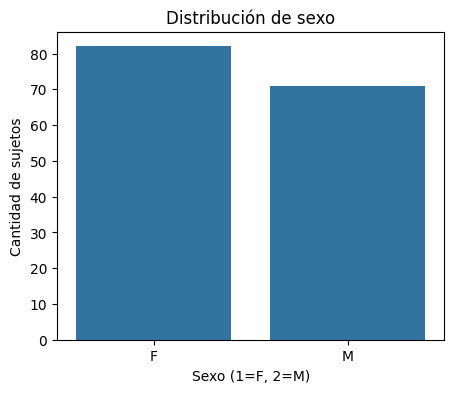

In [41]:
# Balance de la clase 'sex' (F=1)
print('Distribución de la variable \'sex\' \n')
print(sc_subjects['sex (F=1)'].value_counts())
print('*----'*15)
print(sc_subjects['sex (F=1)'].value_counts(normalize=True) * 100)
print('*----'*15 + "\n")

# Gráfica de balanceo de sexo
plt.figure(figsize=(5, 4))
sns.countplot(x='sex (F=1)', data=sc_subjects)
plt.xlabel("Sexo (1=F, 2=M)")
plt.ylabel("Cantidad de sujetos")
plt.title("Distribución de sexo")
plt.xticks(ticks=[0, 1], labels=['F', 'M'])
plt.show()

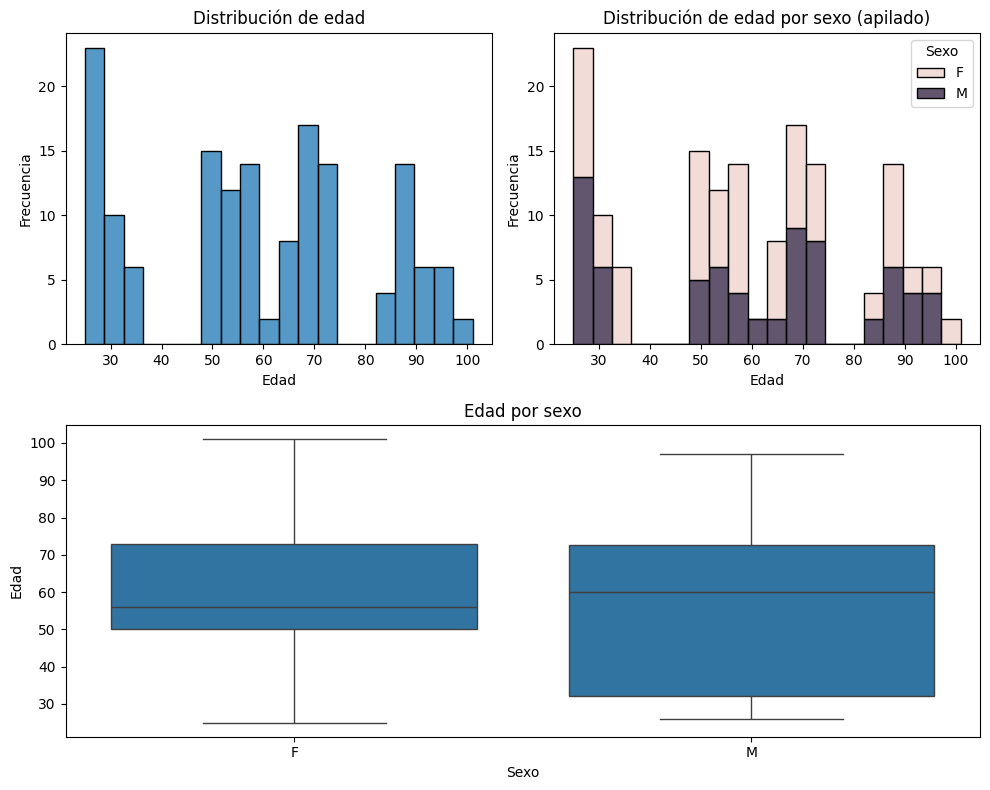

In [49]:
fig, axes = plt.subplot_mosaic(
    [['hist', 'hist_stack'],
     ['box', 'box']],
    figsize=(10, 8)
)

# Histograma simple
sns.histplot(sc_subjects['age'], bins=20, ax=axes['hist'])
axes['hist'].set_xlabel("Edad")
axes['hist'].set_ylabel("Frecuencia")
axes['hist'].set_title("Distribución de edad")

# Histograma apilado por sexo
sns.histplot(
    data=sc_subjects,
    x='age',
    hue='sex (F=1)',
    multiple='stack',
    bins=20,
    ax=axes['hist_stack']
)
axes['hist_stack'].set_xlabel("Edad")
axes['hist_stack'].set_ylabel("Frecuencia")
axes['hist_stack'].set_title("Distribución de edad por sexo (apilado)")

# Boxplot de edad por cada genero
legend = axes['hist_stack'].get_legend()
legend.set_title("Sexo")
for text, label in zip(legend.get_texts(), ['F', 'M']):
    text.set_text(label)

sns.boxplot(x='sex (F=1)', y='age', data=sc_subjects, ax=axes['box'])
axes['box'].set_xlabel("Sexo")
axes['box'].set_ylabel("Edad")
axes['box'].set_title("Edad por sexo")
axes['box'].set_xticks([0, 1])
axes['box'].set_xticklabels(['F', 'M'])

plt.tight_layout()
plt.show()

In [59]:
sc_subjects.groupby('sex (F=1)')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
sex (F=1),,,,,,,,
1,82.0,58.536585,21.475335,25.0,50.0,56.0,73.0,101.0
2,71.0,59.507042,22.980658,26.0,32.0,60.0,72.5,97.0


In [29]:
sc_files = os.listdir("data/sleep-edfx/sleep-cassette")
print(f"Total archivos SC: {len(sc_files)}")
print([f for f in sc_files if "PSG" in f][:5])

Total archivos SC: 306
['SC4312E0-PSG.edf', 'SC4351F0-PSG.edf', 'SC4602E0-PSG.edf', 'SC4091E0-PSG.edf', 'SC4232E0-PSG.edf']


In [71]:
archivos = os.listdir('data/sleep-edfx/sleep-cassette')
psg_sc = [f for f in archivos if "PSG" in f]
hyp_sc = [f for f in archivos if "Hypnogram" in f]
otros_sc = [f for f in archivos if "PSG" not in f and "Hypnogram" not in f]

print(f"SC -> PSG: {len(psg_sc)}, Hypnogram: {len(hyp_sc)}, otros: {len(otros_sc)}")

SC -> PSG: 153, Hypnogram: 153, otros: 0


In [77]:
sc_files = os.listdir("data/sleep-edfx/sleep-cassette")
psg_files = sorted([f for f in sc_files if "PSG" in f])
hyp_files = sorted([f for f in sc_files if "Hypnogram" in f])

print(f"Ejemplos de PSG: {psg_files[:3]}")
print(f"Ejemplos de Hypnogram: {hyp_files[:3]}")

Ejemplos de PSG: ['SC4001E0-PSG.edf', 'SC4002E0-PSG.edf', 'SC4011E0-PSG.edf']
Ejemplos de Hypnogram: ['SC4001EC-Hypnogram.edf', 'SC4002EC-Hypnogram.edf', 'SC4011EH-Hypnogram.edf']


In [99]:
psg_path = "data/sleep-edfx/sleep-cassette/SC4001E0-PSG.edf"

print("Ejemplo SC4001E0-PSG.edf\n")
raw = mne.io.read_raw_edf(psg_path, preload=True)

print(raw.info)
print(raw.ch_names)

Ejemplo SC4001E0-PSG.edf

Extracting EDF parameters from data/sleep-edfx/sleep-cassette/SC4001E0-PSG.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7949999  =      0.000 ... 79499.990 secs...


/tmp/ipykernel_58852/2112328480.py:4: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
/tmp/ipykernel_58852/2112328480.py:4: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
/tmp/ipykernel_58852/2112328480.py:4: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=True)


<Info | 8 non-empty values
 bads: []
 ch_names: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal, Resp oro-nasal, EMG ...
 chs: 7 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 50.0 Hz
 meas_date: 1989-04-24 16:13:00 UTC
 nchan: 7
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: X, sex: 2, first_name: Female, last_name: 33yr>
>
['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']


In [100]:
annot = mne.read_annotations("data/sleep-edfx/sleep-cassette/SC4001EC-Hypnogram.edf")
print("Ejemplo SC4001EC-Hypnogram.edf\n")
print(f"Cantidad de anotaciones para un ejemplo: {len(annot.description)}")
print(f"Ejemplo: {annot.description[:5]}")
print('*----'*20)
print(f"Duración para la anotación del ejemplo: {len(annot.duration)}")
print(f"Ejemplo: {annot.duration[:5]}")

Ejemplo SC4001EC-Hypnogram.edf

Cantidad de anotaciones para un ejemplo: 154
Ejemplo: ['Sleep stage W' 'Sleep stage 1' 'Sleep stage 2' 'Sleep stage 3'
 'Sleep stage 2']
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Duración para la anotación del ejemplo: 154
Ejemplo: [3.063e+04 1.200e+02 3.900e+02 3.000e+01 3.000e+01]


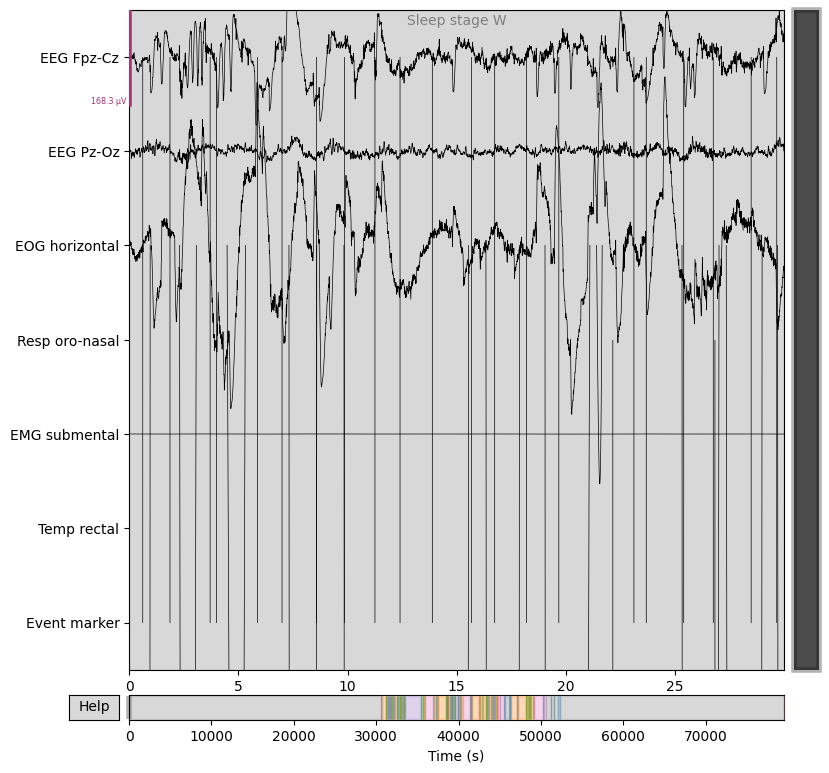

In [101]:
raw.set_annotations(annot, emit_warning=False)
fig = raw.plot(duration=30, n_channels=len(raw.ch_names), scalings='auto', show=True, block=True)

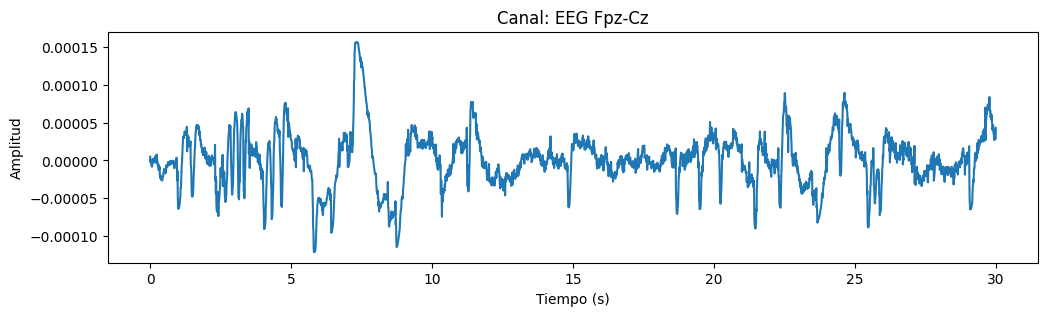

In [102]:
canal = raw.ch_names[0]  # ej. 'EEG Fpz-Cz'
data_canal, times = raw[canal, :3000]

plt.figure(figsize=(12, 3))
plt.plot(times, data_canal.T)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title(f"Canal: {canal}")
plt.show()

## Analisis archivo "ST-subjects.xls"

Los 44 archivos **ST (ST = Sleep Telemetry, o «telemetría del sueño»)** se obtuvieron en un estudio realizado en 1994 sobre los efectos del temazepam en el sueño de 22 hombres y mujeres caucásicos que no tomaban ninguna otra medicación. Los participantes presentaban una dificultad leve para conciliar el sueño, pero por lo demás eran personas sanas. Las PSG (polisomnografías), de aproximadamente 9 horas de duración, se registraron en el hospital durante dos noches: una de ellas después de la ingesta de temazepam y la otra después de la ingesta de un placebo. Los participantes llevaban un sistema de telemetría en miniatura con una calidad de señal muy buena.

Los archivos tienen nombres con el formato **ST7ssNJ0-PSG.edf**, donde:
- ss corresponde al número del participante
- N a la noche.

Las señales de EOG, EMG y EEG se muestrearon a 100 Hz, mientras que el marcador de eventos se muestreó a 1 Hz. La dimensión física del marcador ID+M-E se relaciona con el hecho de que al presionar el botón del marcador (M) se generaban desviaciones de dos segundos respecto a un valor de referencia (baseline). Estas desviaciones permitían identificar la unidad de telemetría (ID = 1 o 2 si el valor era positivo) o indicar un error (E) en el enlace de telemetría si el valor era negativo. Los participantes y las grabaciones se describen con mayor detalle en los encabezados de los archivos, en la hoja de cálculo descriptiva *ST-subjects.xls*.

---

*El siguiente texto fue traducido y adaptado de la información disponible en [Sleep-EDF Database Expanded](https://physionet.org/content/sleep-edfx/1.0.0/#files-panel).*

In [31]:
st_subjects = pd.read_excel("data/sleep-edfx/ST-subjects.xls", skiprows=1)
st_subjects.head()

,Nr,Age,M1/F2,night nr,lights off,night nr.1,lights off.1
0,1,60,1,1,23:01:00,2,23:48:00
1,2,35,2,2,23:27:00,1,00:00:00
2,4,18,2,1,23:53:00,2,22:37:00
3,5,32,2,2,23:23:00,1,23:34:00
4,6,35,2,1,23:28:00,2,23:26:00


In [32]:
print(f'Columnas: {st_subjects.columns}')
print('*----'*20)
print(f'Tamaño del dataset: {st_subjects.shape}')
print('*----'*20)
print(f"Filas duplicadas: {st_subjects.duplicated().sum()}")

Columnas: Index(['Nr', 'Age', 'M1/F2', 'night nr', 'lights off', 'night nr.1',
       'lights off.1'],
      dtype='object')
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Tamaño del dataset: (22, 7)
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Filas duplicadas: 0


In [35]:
print(f"Sujetos duplicados: {st_subjects['Nr'].duplicated().sum() if 'Nr' in st_subjects.columns else 'revisar nombre de columna'}")

Sujetos duplicados: 0


In [36]:
st_subjects.describe()

,Nr,Age,M1/F2,night nr,night nr.1
count,22.000000,22.000000,22.000000,22.000000,22.000000
mean,12.454545,40.181818,1.681818,1.454545,1.545455
std,6.723996,18.094030,0.476731,0.509647,0.509647
min,1.000000,18.000000,1.000000,1.000000,1.000000
25%,7.250000,22.500000,1.000000,1.000000,1.000000
50%,12.500000,35.000000,2.000000,1.000000,2.000000
75%,17.750000,52.500000,2.000000,2.000000,2.000000
max,24.000000,79.000000,2.000000,2.000000,2.000000


Distribución de la variable 'sex' 

M1/F2
2    15
1     7
Name: count, dtype: int64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
M1/F2
2    68.181818
1    31.818182
Name: proportion, dtype: float64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----



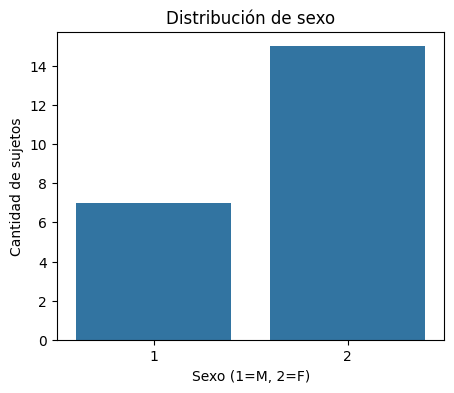

In [37]:
# Balance de la clase 'sex' (F=1)
print('Distribución de la variable \'sex\' \n')
print(st_subjects['M1/F2'].value_counts())
print('*----'*15)
print(st_subjects['M1/F2'].value_counts(normalize=True) * 100)
print('*----'*15 + "\n")

# Gráfica de balanceo de sexo
plt.figure(figsize=(5, 4))
sns.countplot(x='M1/F2', data=st_subjects)
plt.xlabel("Sexo (1=M, 2=F)")
plt.ylabel("Cantidad de sujetos")
plt.title("Distribución de sexo")
plt.show()

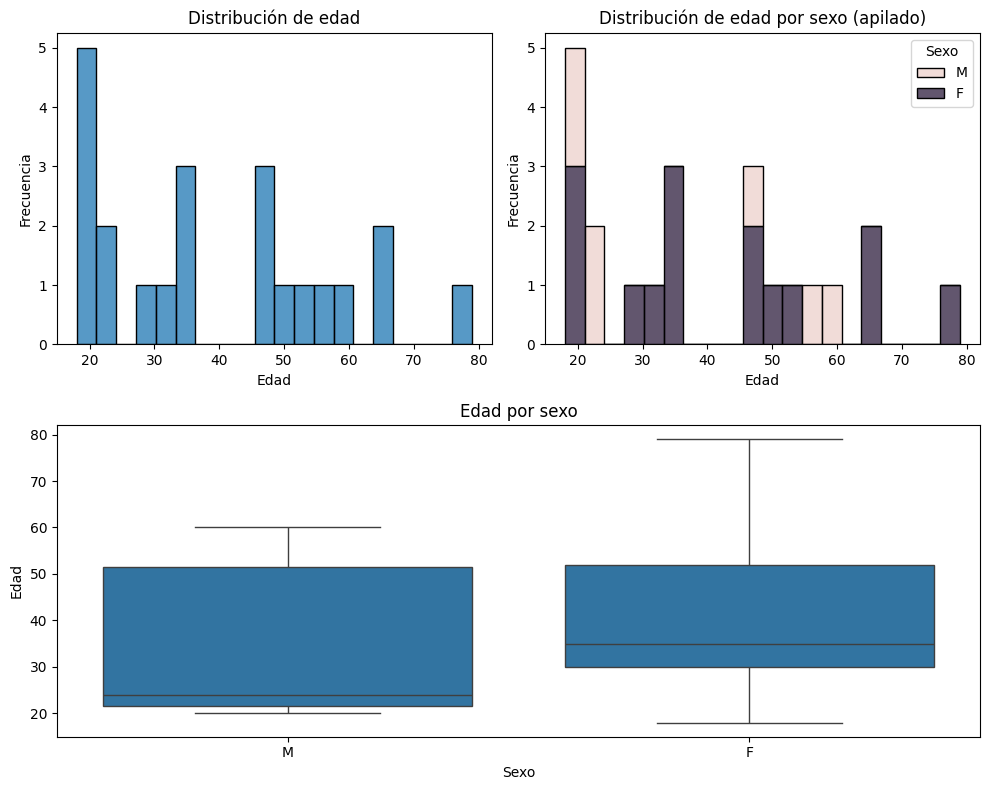

In [54]:
fig, axes = plt.subplot_mosaic(
    [['hist', 'hist_stack'],
     ['box', 'box']],
    figsize=(10, 8)
)

# Histograma simple
sns.histplot(st_subjects['Age'], bins=20, ax=axes['hist'])
axes['hist'].set_xlabel("Edad")
axes['hist'].set_ylabel("Frecuencia")
axes['hist'].set_title("Distribución de edad")

# Histograma apilado por sexo
sns.histplot(
    data=st_subjects,
    x='Age',
    hue='M1/F2',
    multiple='stack',
    bins=20,
    ax=axes['hist_stack']
)
axes['hist_stack'].set_xlabel("Edad")
axes['hist_stack'].set_ylabel("Frecuencia")
axes['hist_stack'].set_title("Distribución de edad por sexo (apilado)")


legend = axes['hist_stack'].get_legend()
legend.set_title("Sexo")
for text, label in zip(legend.get_texts(), ['M', 'F']):
    text.set_text(label)

# Boxplot de edad por cada genero
sns.boxplot(x='M1/F2', y='Age', data=st_subjects, ax=axes['box'])
axes['box'].set_xlabel("Sexo")
axes['box'].set_ylabel("Edad")
axes['box'].set_title("Edad por sexo")
axes['box'].set_xticks([0, 1])
axes['box'].set_xticklabels(['M', 'F'])

plt.tight_layout()
plt.show()

In [58]:
st_subjects.groupby('M1/F2')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
M1/F2,,,,,,,,
1,7.0,35.714286,17.876561,20.0,21.5,24.0,51.5,60.0
2,15.0,42.266667,18.425397,18.0,30.0,35.0,52.0,79.0


In [60]:
st_files = os.listdir("data/sleep-edfx/sleep-telemetry")
print(f"Total archivos ST: {len(sc_files)}")
print([f for f in sc_files if "PSG" in f][:5])

Total archivos ST: 306
['SC4312E0-PSG.edf', 'SC4351F0-PSG.edf', 'SC4602E0-PSG.edf', 'SC4091E0-PSG.edf', 'SC4232E0-PSG.edf']


In [62]:
with open("data/sleep-edfx/RECORDS") as f:
    records = [line.strip() for line in f.readlines()]

print(f"Total de archivos esperados: {len(records)}")
print(records[:5])

Total de archivos esperados: 197
['sleep-cassette/SC4001E0-PSG.edf', 'sleep-cassette/SC4002E0-PSG.edf', 'sleep-cassette/SC4011E0-PSG.edf', 'sleep-cassette/SC4012E0-PSG.edf', 'sleep-cassette/SC4021E0-PSG.edf']


In [72]:
archivos = os.listdir('data/sleep-edfx/sleep-telemetry')
psg_st = [f for f in archivos if "PSG" in f]
hyp_st = [f for f in archivos if "Hypnogram" in f]
otros_st = [f for f in archivos if "PSG" not in f and "Hypnogram" not in f]

print(f"ST -> PSG: {len(psg_st)}, Hypnogram: {len(hyp_st)}, otros: {len(otros_st)}")

ST -> PSG: 44, Hypnogram: 44, otros: 0


In [90]:
st_files = os.listdir("data/sleep-edfx/sleep-telemetry")
psg_files = sorted([f for f in st_files if "PSG" in f])
hyp_files = sorted([f for f in st_files if "Hypnogram" in f])

print(f"Ejemplos de PSG: {psg_files[:3]}")
print(f"Ejemplos de Hypnogram: {hyp_files[:3]}")

Ejemplos de PSG: ['ST7011J0-PSG.edf', 'ST7012J0-PSG.edf', 'ST7021J0-PSG.edf']
Ejemplos de Hypnogram: ['ST7011JP-Hypnogram.edf', 'ST7012JP-Hypnogram.edf', 'ST7021JM-Hypnogram.edf']


In [106]:
psg_path = "data/sleep-edfx/sleep-telemetry/ST7011J0-PSG.edf"

print("Ejemplo ST7011J0-PSG.edf\n")
st_raw = mne.io.read_raw_edf(psg_path, preload=True)

print(st_raw.info)
print(st_raw.ch_names)

Ejemplo ST7011J0-PSG.edf

Extracting EDF parameters from data/sleep-edfx/sleep-telemetry/ST7011J0-PSG.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3589999  =      0.000 ... 35899.990 secs...


/tmp/ipykernel_58852/365837900.py:4: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  st_raw = mne.io.read_raw_edf(psg_path, preload=True)
/tmp/ipykernel_58852/365837900.py:4: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  st_raw = mne.io.read_raw_edf(psg_path, preload=True)


<Info | 8 non-empty values
 bads: []
 ch_names: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal, EMG submental, Marker
 chs: 5 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 800.0 Hz
 meas_date: 1994-07-12 23:00:00 UTC
 nchan: 5
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: X, sex: 1, first_name: Male, last_name: 60yr>
>
['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'EMG submental', 'Marker']


In [104]:
st_annot = mne.read_annotations("data/sleep-edfx/sleep-telemetry/ST7011JP-Hypnogram.edf")
print("Ejemplo ST7011JP-Hypnogram.edf\n")
print(f"Cantidad de anotaciones para un ejemplo: {len(st_annot.description)}")
print(f"Ejemplo: {st_annot.description[:5]}")
print('*----'*20)
print(f"Duración para la anotación del ejemplo: {len(st_annot.duration)}")
print(f"Ejemplo: {st_annot.duration[:5]}")

Ejemplo ST7011JP-Hypnogram.edf

Cantidad de anotaciones para un ejemplo: 231
Ejemplo: ['Sleep stage W' 'Sleep stage 1' 'Sleep stage 2' 'Sleep stage 1'
 'Sleep stage 2']
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Duración para la anotación del ejemplo: 231
Ejemplo: [1560.   90.  570.  120.   60.]


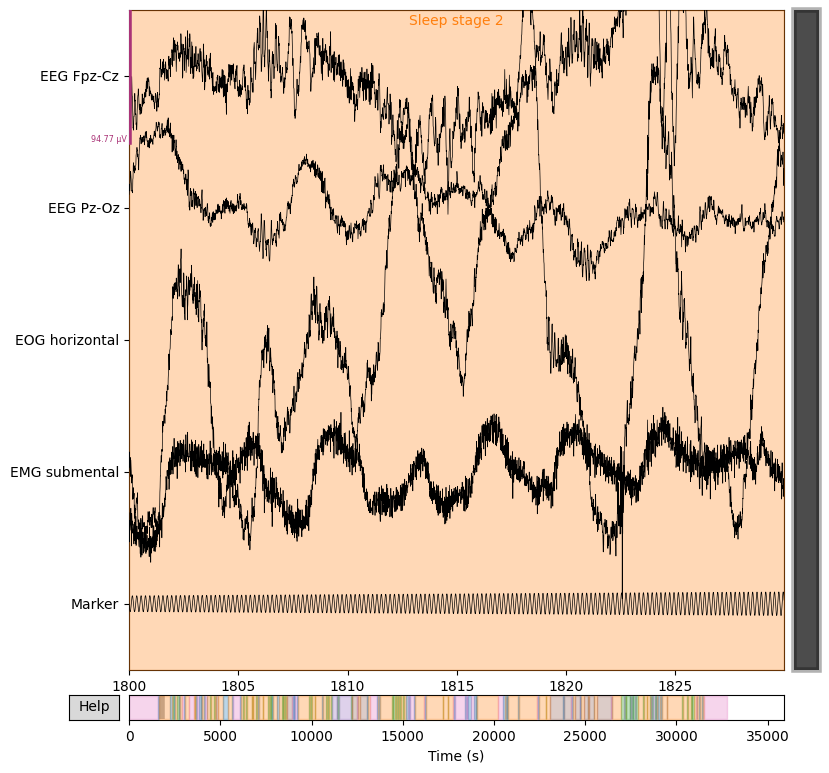

In [108]:
st_raw.set_annotations(st_annot, emit_warning=False)
fig = st_raw.plot(start=1800, duration=30, n_channels=len(st_raw.ch_names), scalings='auto', show=True, block=True)

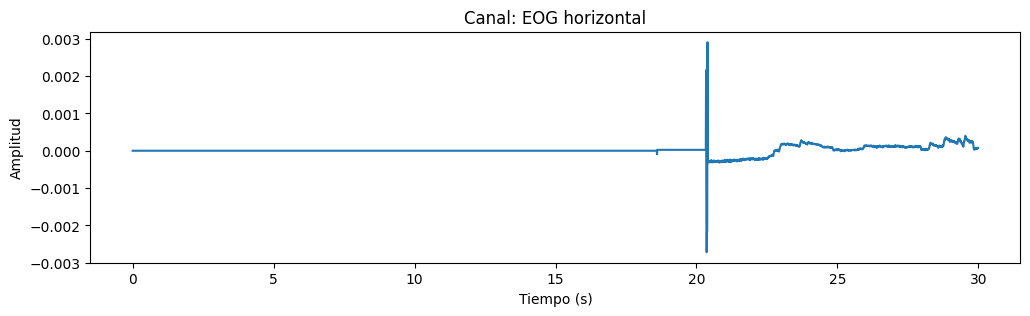

In [109]:
canal = st_raw.ch_names[2]  # 'EEG Horizontal'
data_canal, times = st_raw[canal, :3000]

plt.figure(figsize=(12, 3))
plt.plot(times, data_canal.T)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title(f"Canal: {canal}")
plt.show()

## Target

In [110]:
def contar_etapas_sujeto(hyp_path):
    annot = mne.read_annotations(hyp_path)
    return pd.Series(annot.description).value_counts()

In [125]:
def contar_etapas_carpeta(carpeta):
    archivos = os.listdir(carpeta)
    hyp_files = [f for f in archivos if "Hypnogram" in f]

    conteo_total = pd.Series(dtype=int)
    for hyp_f in hyp_files:
        hyp_path = os.path.join(carpeta, hyp_f)
        try:
            conteo = contar_etapas_sujeto(hyp_path)
            conteo_total = conteo_total.add(conteo, fill_value=0)
        except Exception as e:
            print(f"Error en {hyp_f}: {e}")

    return conteo_total.astype(int)

conteo_sc = contar_etapas_carpeta("data/sleep-edfx/sleep-cassette")
conteo_st = contar_etapas_carpeta("data/sleep-edfx/sleep-telemetry")

print("SC:\n", conteo_sc)
print('*----'*15)
porcentajes = conteo_sc / conteo_sc.sum() * 100
for etapa, pct in porcentajes.items():
    print(f"{etapa}: {pct:.2f}%")
print('*----'*15)
print("\nST:\n", conteo_st)
print('*----'*15)
porcentajes = conteo_st / conteo_st.sum() * 100
for etapa, pct in porcentajes.items():
    print(f"{etapa}: {pct:.2f}%")

SC:
 Movement time     123
Sleep stage 1    5944
Sleep stage 2    6378
Sleep stage 3    3538
Sleep stage 4    1015
Sleep stage ?     174
Sleep stage R    1560
Sleep stage W    3698
dtype: int64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Movement time: 0.55%
Sleep stage 1: 26.50%
Sleep stage 2: 28.44%
Sleep stage 3: 15.77%
Sleep stage 4: 4.53%
Sleep stage ?: 0.78%
Sleep stage R: 6.95%
Sleep stage W: 16.49%
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----

ST:
 Movement time      73
Sleep stage 1    1348
Sleep stage 2    1793
Sleep stage 3    1282
Sleep stage 4     447
Sleep stage R     393
Sleep stage W     763
dtype: int64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Movement time: 1.20%
Sleep stage 1: 22.10%
Sleep stage 2: 29.40%
Sleep stage 3: 21.02%
Sleep stage 4: 7.33%
Sleep stage R: 6.44%
Sleep stage W: 12.51%


In [122]:
conteo_total = conteo_sc.add(conteo_st, fill_value=0).astype(int)
total_general = conteo_total.sum()
print(f"Total de anotaciones (SC + ST): {total_general}")
print('*----'*15)
porcentajes = conteo_total / total_general * 100

for etapa, pct in porcentajes.items():
    print(f"{etapa}: {pct:.2f}%")

Total de anotaciones (SC + ST): 28529
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Movement time: 0.69%
Sleep stage 1: 25.56%
Sleep stage 2: 28.64%
Sleep stage 3: 16.90%
Sleep stage 4: 5.12%
Sleep stage ?: 0.61%
Sleep stage R: 6.85%
Sleep stage W: 15.64%


In [115]:
conteo_sc

,0
Movement time,123
Sleep stage 1,5944
Sleep stage 2,6378
Sleep stage 3,3538
Sleep stage 4,1015
Sleep stage ?,174
Sleep stage R,1560
Sleep stage W,3698


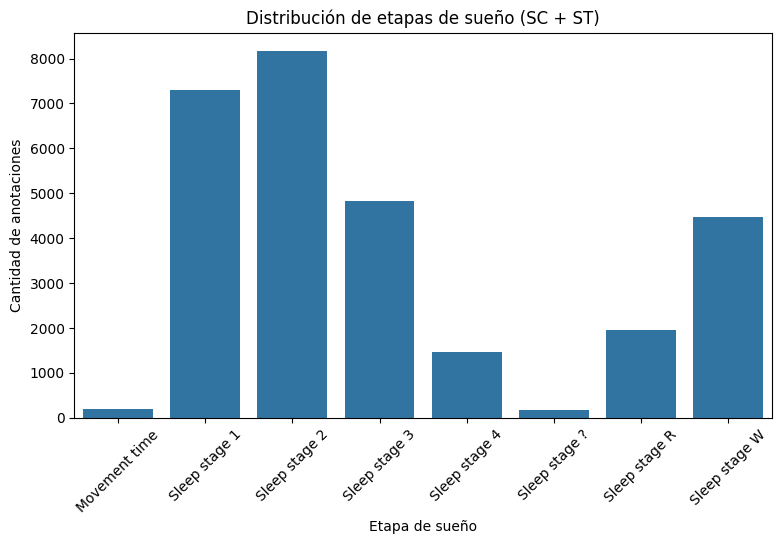

In [113]:
plt.figure(figsize=(9, 5))
sns.barplot(x=conteo_total.index, y=conteo_total.values)
plt.xlabel("Etapa de sueño")
plt.ylabel("Cantidad de anotaciones")
plt.title("Distribución de etapas de sueño (SC + ST)")
plt.xticks(rotation=45)
plt.show()

## Conclusiones

Por medio del EDA inicial se puede concluir lo siguiente:
- EL total de anotaciones que se tiene para el dataset es de 28.529, sin embargo acá se debe tener cuidado al hacer el split para el entrenamiento, dado que esos registros corresponden a 197 casos distintos.
- Se observa un claro desbalance de clases en ambos datasets (N3/N4/REM/Movement son minoritarias), por lo que el feature engineering y el modelado deberán incluir manejo de desbalance.
- Los archivos "SC-subjects.xls" y "ST-subjects.xls" permiten mapear de una forma adecuada cada  registro PSG/Hypnogram con la información demográfica del sujeto (edad, sexo) y, en el caso de  ST, la condición experimental (placebo o temazepam) según la noche grabada. Esto es clave para  poder incluir estas variables como features adicionales en el modelo, y no solo como metadatos descriptivos del EDA.
- Se observa "SC-subjects.xls" y "ST-subjects.xls", no tienen la misma cantidad de canales, el archivo de telemtria no posee los canales 'Resp oro-nasal' y 'Temp rectal'.
- El análisis inicial permite conocer los archivos para la construcción del dataset, identificando cómo se relacionan los PSG, los Hypnograms y las hojas de sujetos (SC-subjects.xls, ST-subjects.xls)  mediante el número de sujeto y noche. Esto sienta la base para armar un dataset limpio, con el target (etapa de sueño) correctamente vinculado a cada señal y a sus covariables (edad, sexo, condición experimental).